<a href="https://colab.research.google.com/github/student-uzma/CSL701-CS10_Machine-Learning-Lab/blob/main/ML_Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name : Uzma Moh.Rafiq Choudhary

Batch : CS1


Roll Number : CS10



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Upload the zip (Colab) and extract it
from google.colab import files
uploaded = files.upload()
zip_name = list(uploaded.keys())[0]
with zipfile.ZipFile(zip_name) as z:
    z.extractall('.')
print("Files available:", os.listdir('.'))

# Load dataset
df = pd.read_csv('Mall_Customers.csv')
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
df.head()

Saving archive (14).zip to archive (14).zip
Files available: ['.config', 'Mall_Customers.csv', 'archive (14).zip', 'sample_data']
Shape: (200, 5)

Missing values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [2]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Mean after scaling:", X_scaled.mean(axis=0).round(3))
print("Std after scaling :", X_scaled.std(axis=0).round(3))
print("Scaled shape:", X_scaled.shape)

Mean after scaling: [-0. -0.]
Std after scaling : [1. 1.]
Scaled shape: (200, 2)


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

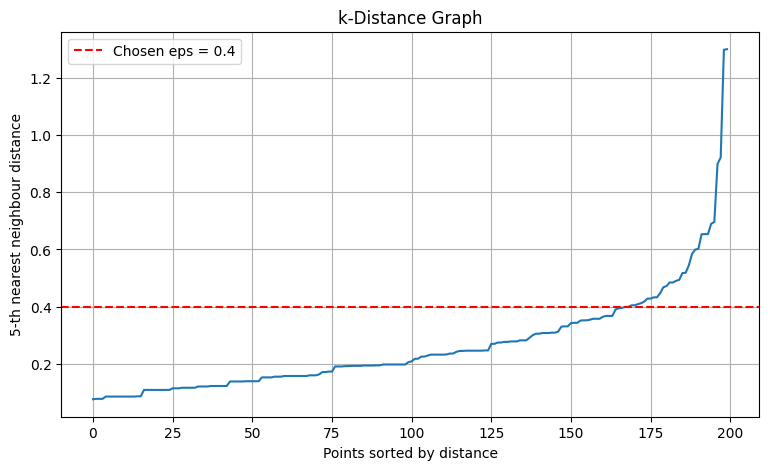

In [3]:
min_samples = 5

nn = NearestNeighbors(n_neighbors=min_samples)
nn.fit(X_scaled)
distances, indices = nn.kneighbors(X_scaled)

# distance to the k-th nearest neighbour (k = min_samples), sorted
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.axhline(y=0.4, color='r', linestyle='--', label='Chosen eps = 0.4')
plt.xlabel("Points sorted by distance")
plt.ylabel(f"{min_samples}-th nearest neighbour distance")
plt.title("k-Distance Graph")
plt.legend()
plt.grid(True)
plt.show()

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

Unique labels: [-1  0  1  2  3]
Core points  : 169
Border points: 16
Noise points : 15


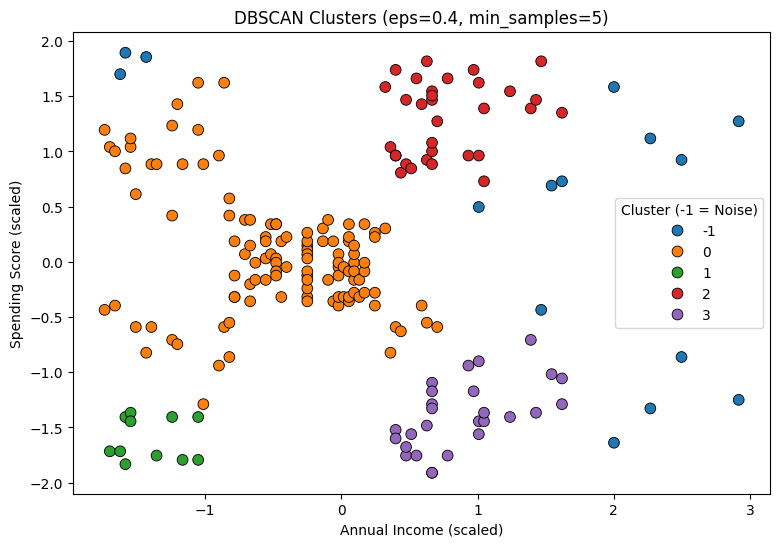

In [4]:
eps = 0.4
min_samples = 5

dbscan = DBSCAN(eps=eps, min_samples=min_samples)
labels = dbscan.fit_predict(X_scaled)

print("Unique labels:", np.unique(labels))

# Point classification: core, border, noise
core_mask = np.zeros(len(labels), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True
noise_mask = labels == -1
border_mask = ~core_mask & ~noise_mask

print("Core points  :", core_mask.sum())
print("Border points:", border_mask.sum())
print("Noise points :", noise_mask.sum())

# Visualize
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], hue=labels,
                palette='tab10', s=60, edgecolor='k')
plt.xlabel("Annual Income (scaled)")
plt.ylabel("Spending Score (scaled)")
plt.title(f"DBSCAN Clusters (eps={eps}, min_samples={min_samples})")
plt.legend(title="Cluster (-1 = Noise)")
plt.show()

# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [6]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = (labels == -1).sum()

print("Number of clusters (excluding noise):", n_clusters)
print("Number of noise points              :", n_noise)
print("Noise percentage                    : {:.2f}%".format(n_noise / len(labels) * 100))

# Silhouette score needs at least 2 clusters
if n_clusters > 1:
    mask = labels != -1
    print("Silhouette Score (excluding noise)  :", round(silhouette_score(X_scaled[mask], labels[mask]), 4))
    print("Silhouette Score (including noise)  :", round(silhouette_score(X_scaled, labels), 4))
else:
    print("Silhouette Score cannot be computed: fewer than 2 clusters found.")

Number of clusters (excluding noise): 4
Number of noise points              : 15
Noise percentage                    : 7.50%
Silhouette Score (excluding noise)  : 0.4781
Silhouette Score (including noise)  : 0.4133


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

         Count  Avg_Income  Avg_Spending  Avg_Age
Cluster                                          
-1          15       96.13         61.80    34.53
 0         115       48.30         51.73    39.54
 1          11       23.73          8.91    49.36
 2          32       80.88         83.62    32.75
 3          27       83.93         14.44    41.26

Noise points (outliers):
     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
7             8  Female   23                  18                      94
11           12  Female   35                  19                      99
19           20  Female   35                  23                      98
169         170    Male   32                  87                      63
184         185  Female   41                  99                      39
187         188    Male   28                 101                      68
191         192  Female   32                 103                      69
192         193    Male   33            

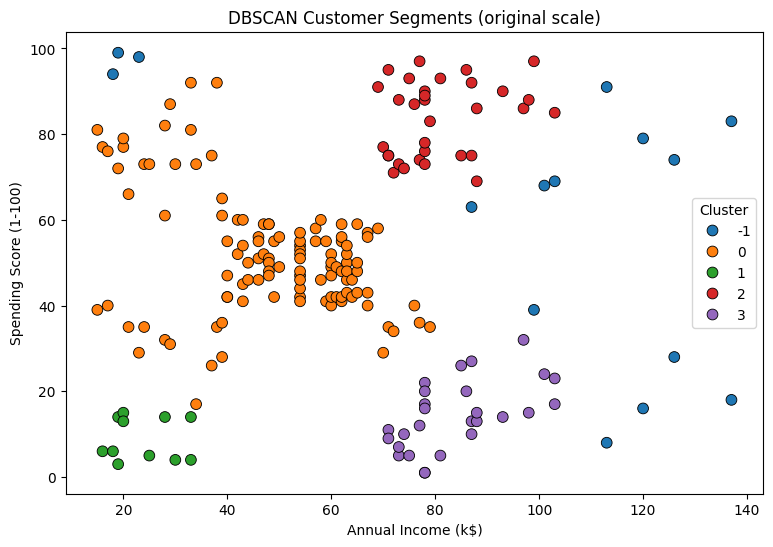

In [7]:
df['Cluster'] = labels

cluster_stats = df.groupby('Cluster').agg(
    Count=('CustomerID', 'count'),
    Avg_Income=('Annual Income (k$)', 'mean'),
    Avg_Spending=('Spending Score (1-100)', 'mean'),
    Avg_Age=('Age', 'mean')
).round(2)
print(cluster_stats)

print("\nNoise points (outliers):")
print(df[df['Cluster'] == -1][['CustomerID', 'Gender', 'Age'] + features])

# Visualize in original units
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Cluster', palette='tab10', s=60, edgecolor='k')
plt.title("DBSCAN Customer Segments (original scale)")
plt.show()

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.